<a href="https://colab.research.google.com/github/tyniquex/big-data-analytics-isda-130/blob/main/data_profile.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 1 | Data Profile & Quality Audit

**3 points · due Sunday, August 30, 11:59pm PT**

Before you analyse a dataset you profile it. This notebook profiles the dataset you intend to
commit to for the semester, and the profile is also your Project 0.

## How this notebook works

**Parts 1 to 5 are written for you.** You fill in three variables at
the top, run everything, and read the output.

**Parts 6, 7 and 8 are yours.** They are where the 3 points live.

| You do | Where |
|---|---|
| Name your dataset | TODO 1 |
| Say whether the documentation names an identifier column | TODO 2 |
| Say which free-text column you will carry to Weeks 8 to 10 | TODO 3 |
| Write the provenance note | Part 6 |
| Write the six-row quality audit | Part 7 |
| Write two questions and a verdict | Part 8 |

## Grading

| Pt | Earned by |
|---|---|
| 1 | The self-check at the end prints a clean report: dataset named, all parts run in order, Parts 6 to 8 filled |
| 1 | Part 6 carries the documentation URL, a quoted sentence about collection **or** an explicit statement that the page has none, and one named exclusion tied to a number from Parts 1 to 5 |
| 1 | Parts 7 and 8 cite specific numbers from **your** profile. A row written in general terms, with no number, does not count |

## Before you start

Run **Runtime → Disconnect and delete runtime**, then **Runtime → Run all**. That is the state your
notebook will be read in.

## Part 0: Runtime and versions

Reports what this runtime actually has. Nothing to edit.

In [ ]:
# --- Runtime and versions ----------------------------------------------------
import sys, platform, datetime, importlib

_ran = []          # every part appends to this; the self-check reads it
_started = datetime.datetime.now()

def _require(step, human):
    """Stop with one clear sentence instead of a cascade of NameErrors."""
    if step not in _ran:
        raise RuntimeError(f"STOP. {human} Nothing below this cell will work until you do.")

def _done(step):
    """Record that a part finished. Re-running a cell does not record it twice."""
    if step not in _ran:
        _ran.append(step)

print("run started :", _started.strftime("%Y-%m-%d %H:%M:%S"))
print("python      :", sys.version.split()[0])
print("platform    :", platform.platform())
for _n in ("pandas", "numpy", "matplotlib", "pyarrow"):
    try:
        print(f"{_n:12s}:", getattr(importlib.import_module(_n), "__version__", "unknown"))
    except ImportError:
        print(f"{_n:12s}: NOT INSTALLED")
_done("part0")

run started : 2026-08-31 05:07:01
python      : 3.13.15
platform    : Linux-6.6.122+-x86_64-with-glibc2.35
pandas      : 2.2.3
numpy       : 2.1.3
matplotlib  : 3.10.0
pyarrow     : 18.1.0


## TODO 1: name your dataset

Fill in all three. `source` can be a URL or a path to a `.csv`, `.csv.gz`, `.parquet`, or `.json`.

- Using the **course default**? Paste the Drive link from the Week 2 page.
- Using a **Hugging Face** dataset? Set `source = "hf:<dataset-id>"`, for example `"hf:stanfordnlp/imdb"`.
- Using **Kaggle**? Download the file first, upload it to this session with the folder icon on the left, and set `source` to the filename.

`doc_url` is the page that describes how the data was collected. **You need it in Part 6.** If you
cannot find one, put the closest page you did check. Do not leave it blank.

In [ ]:
# TODO 1: fill in all three, between the quotes.
DATASET_CHOICE = {

    # A short name. Anything you will recognise later.
    #   e.g.  "CFPB Consumer Complaints, 2025 sample"
    "name":    "IMDB Movie Reviews",

    # Where the file is. Pick whichever one matches your dataset:
    #   the course default ........  paste the link from the Week 2 page
    #   a Hugging Face dataset ....  "hf:stanfordnlp/imdb"
    #   a file you uploaded .......  "winemag-data-130k-v2.csv"
    #        (upload with the folder icon on the left, then use the filename)
    "source":  "hf:stanfordnlp/imdb",

    # The page that says HOW the data was collected. You need it in Part 6.
    #   e.g.  "https://ai.stanford.edu/~amaas/data/sentiment/"
    "doc_url": "https://huggingface.co/datasets/stanfordnlp/imdb",
}

assert "REPLACE ME" not in DATASET_CHOICE.values(), (
    "Fill in all three fields of DATASET_CHOICE before running the rest of the notebook.")
_done("todo1")
print("dataset :", DATASET_CHOICE["name"])
print("source  :", DATASET_CHOICE["source"])
print("docs    :", DATASET_CHOICE["doc_url"])

dataset : IMDB Movie Reviews
source  : hf:stanfordnlp/imdb
docs    : https://huggingface.co/datasets/stanfordnlp/imdb


## Part 1: Identity

Loads the file and reports what it is. Nothing to edit.

In [ ]:
# --- Part 1: identity --------------------------------------------------------
_require("todo1", "Fill in all three fields of DATASET_CHOICE (TODO 1) and run that cell.")
import pandas as pd, numpy as np, io, re

_DRIVE_RE = re.compile(r"drive\.google\.com/(?:file/d/|open\?id=|uc\?(?:[^&]*&)*id=)([\w-]+)")

def _read_drive(file_id):
    """A Google Drive share link points at a web page, not at the file.

    This fetches the bytes from Drive's direct-download endpoint and works out the
    format from the first few bytes, because the URL has no filename to read it from.
    """
    import urllib.request
    url = f"https://drive.google.com/uc?export=download&id={file_id}"
    with urllib.request.urlopen(url, timeout=180) as r:
        blob = r.read()
    head = blob[:64].lstrip().lower()
    if head.startswith(b"<!doctype") or head.startswith(b"<html"):
        raise RuntimeError(
            "Google Drive sent a web page instead of the file.\n"
            "Usually one of two things:\n"
            "  1. the file is not shared as 'Anyone with the link'\n"
            "  2. Drive is showing a virus-scan warning, or the daily download limit was hit\n"
            "Ask on the Week 2 discussion if it is number 2 - it is not something you can fix.")
    if blob[:2] == b"\x1f\x8b":
        return pd.read_csv(io.BytesIO(blob), compression="gzip", low_memory=False)
    if blob[:4] == b"PAR1":
        return pd.read_parquet(io.BytesIO(blob))
    return pd.read_csv(io.BytesIO(blob), low_memory=False)

def load_any(src):
    """Load a dataset from a URL, a Google Drive link, a local path, or a Hugging Face id."""
    if src.startswith("hf:"):
        from datasets import load_dataset
        ds = load_dataset(src[3:], split="train")
        return ds.to_pandas()
    m = _DRIVE_RE.search(src)
    if m:
        return _read_drive(m.group(1))
    low = src.lower().split("?")[0]
    if low.endswith(".parquet"):            return pd.read_parquet(src)
    if low.endswith((".csv", ".csv.gz", ".gz")): return pd.read_csv(src, low_memory=False)
    if low.endswith((".json", ".jsonl")):   return pd.read_json(src, lines=low.endswith(".jsonl"))
    # last resort: try csv
    return pd.read_csv(src, low_memory=False)

df = load_any(DATASET_CHOICE["source"])

print(f"rows x columns : {df.shape[0]:,} x {df.shape[1]}")
print(f"memory         : {df.memory_usage(deep=True).sum()/1e6:,.1f} MB\n")
print("column types:")
for c in df.columns:
    print(f"  {str(df[c].dtype):10s}  {c}")
_done("part1")
df.head()

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

rows x columns : 25,000 x 2
memory         : 34.6 MB

column types:
  object      text
  int64       label


,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


## TODO 2 and 3: two judgement calls

**TODO 2.** Does your dataset's documentation name a column that uniquely identifies one record?
If yes, put its exact name. **If the documentation does not name one, leave it as `None`.** Do not
guess from column names.

**TODO 3.** Which free-text column will you carry to Weeks 8 to 10? Leave `None` and the notebook
picks the column with the longest average text, then tells you what it picked. If that is not the
one you want, name it yourself.

In [ ]:
# TODO 2: does your dataset's DOCUMENTATION name a column that identifies one record?
#   Read the page. Do not guess from column names.
#   it does     ->  put the exact name, e.g.  "Complaint ID"
#   it does not ->  leave it as None. That is a real answer and Part 3 will report it.
ID_COLUMN = None

# TODO 3: which free-text column will you carry to Weeks 8 to 10?
#   you know which one  ->  put the exact name, e.g.  "Consumer complaint narrative"
#   not sure yet        ->  leave "AUTO" and the notebook picks the longest one and tells you
TEXT_COLUMN = "text"

# --- resolve TEXT_COLUMN ------------------------------------------------------
_require("part1", "Part 1 did not finish. Read its error, fix the source in TODO 1, and re-run Part 1.")

def pick_text_column(frame):
    best, best_len = None, 0
    for c in frame.columns:
        if frame[c].dtype != object: continue
        s = frame[c].dropna().astype(str)
        if len(s) == 0: continue
        m = s.str.len().mean()
        if m > best_len: best, best_len = c, m
    return best, best_len

if TEXT_COLUMN is None:
    TEXT_COLUMN, _avg = pick_text_column(df)
    print(f"TEXT_COLUMN not set. Chose {TEXT_COLUMN!r} (mean length {_avg:.0f} characters).")
    print("If that is not the column you will use in Weeks 8 to 10, set TEXT_COLUMN yourself.")
else:
    print(f"TEXT_COLUMN set by you: {TEXT_COLUMN!r}")
    assert TEXT_COLUMN in df.columns, f"{TEXT_COLUMN!r} is not a column in this dataset."

if ID_COLUMN is None:
    print("\nID_COLUMN is None. Part 3 will report that the documentation names no identifier.")
else:
    assert ID_COLUMN in df.columns, f"{ID_COLUMN!r} is not a column in this dataset."
    print(f"\nID_COLUMN set by you: {ID_COLUMN!r}")
_done("todo23")

TEXT_COLUMN set by you: 'text'

ID_COLUMN is None. Part 3 will report that the documentation names no identifier.


## Part 2: Missingness, counted twice

`isna()` finds the values that were stored as null. It does not find an empty string, three spaces,
the text `"N/A"`, or a number like `-999` that somebody chose to mean "we don't have this."

This part counts both ways and reports **where the two counts disagree**. That gap is what your
audit reports, not the `isna()` number.

Zeros are scanned but reported **separately** and are **not** counted as missing. A zero is
ambiguous: it can mean a real zero or a placeholder. If you decide a zero column is really missing
data, say so in Part 7 with a reason.

In [ ]:
# --- Part 2: missingness, twice ----------------------------------------------
_require("todo23", "TODO 2 and 3 have not run. Run that cell first.")

SENTINEL_STRINGS = {"", "n/a", "na", "n.a.", "none", "null", "nil", "unknown", "unspecified",
                    "not available", "not applicable", "-", "--", "?", "missing", "xxxx"}
SENTINEL_NUMBERS = {-999, -9999, -1e9}

def sentinel_mask(s):
    """True where the value is missing, including values wearing a disguise."""
    m = s.isna()
    if s.dtype == object:
        t = s.astype("string").str.strip().str.lower()
        m = m | t.isin(SENTINEL_STRINGS) | (t.str.len() == 0)
    elif np.issubdtype(s.dtype, np.number):
        m = m | s.isin(list(SENTINEL_NUMBERS))
    return m.fillna(False)

rows = []
for c in df.columns:
    na  = int(df[c].isna().sum())
    sen = int(sentinel_mask(df[c]).sum())
    zeros = int((df[c] == 0).sum()) if np.issubdtype(df[c].dtype, np.number) else 0
    rows.append({"column": c, "isna": na, "sentinel": sen, "gap": sen - na,
                 "pct_missing": round(sen / len(df) * 100, 1), "zeros": zeros})
miss = pd.DataFrame(rows).sort_values(["gap", "pct_missing"], ascending=False).reset_index(drop=True)

print("Per-column missingness. 'gap' is what isna() did not see.\n")
print(miss.to_string(index=False))

hidden = miss[miss["gap"] > 0]
print("\n" + "-"*70)
if len(hidden):
    print(f"{len(hidden)} column(s) have missing values that isna() does not report.")
    print("The three worst, and what is hiding in them:\n")
    for c in hidden["column"].head(3):
        vals = df.loc[sentinel_mask(df[c]) & ~df[c].isna(), c]
        shown = sorted({repr(v) for v in vals.head(200)})[:6]
        print(f"  {c}")
        print(f"    isna {int(df[c].isna().sum()):,}  ->  真 missing {int(sentinel_mask(df[c]).sum()):,}"
              .replace("真", "actually"))
        print(f"    hiding: {', '.join(shown)}")
else:
    print("No column has disguised missing values. Say so in Part 7; it is an unusual result.")

zc = miss[miss["zeros"] > 0]
if len(zc):
    print("\nColumns containing zeros (NOT counted as missing above):")
    for _, r in zc.iterrows():
        print(f"  {r['column']}: {r['zeros']:,} zeros ({r['zeros']/len(df)*100:.1f}%)")
    print("  If a zero here means 'not recorded', say so in Part 7 and give your reason.")
_done("part2")

Per-column missingness. 'gap' is what isna() did not see.

column  isna  sentinel  gap  pct_missing  zeros
  text     0         0    0          0.0      0
 label     0         0    0          0.0  12500

----------------------------------------------------------------------
No column has disguised missing values. Say so in Part 7; it is an unusual result.

Columns containing zeros (NOT counted as missing above):
  label: 12,500 zeros (50.0%)
  If a zero here means 'not recorded', say so in Part 7 and give your reason.


## Part 3: Duplicates

Two different questions. Are any two rows identical across every column? And does the column that
is supposed to identify one record actually identify it once?

In [ ]:
# --- Part 3: duplicates -------------------------------------------------------
_require("part2", "Part 2 has not run. Run it first.")

exact = int(df.duplicated().sum())
print(f"exact duplicate rows : {exact:,}  ({exact/len(df)*100:.2f}% of the file)")
if exact:
    print("  first two examples:")
    print(df[df.duplicated(keep=False)].head(2).to_string())

print()
if ID_COLUMN is None:
    print("identifier column    : the documentation does not name one (ID_COLUMN is None).")
    print("  Report that in Part 7 under uniqueness. It is a complete answer.")
else:
    dup_id = int(df.duplicated(subset=[ID_COLUMN]).sum())
    nun    = int(df[ID_COLUMN].nunique(dropna=True))
    print(f"identifier column    : {ID_COLUMN}")
    print(f"  distinct values    : {nun:,} of {len(df):,} rows")
    print(f"  rows sharing an id : {dup_id:,}")
    if dup_id:
        worst = df[ID_COLUMN].value_counts().head(3)
        print(f"  most repeated ids  : {dict(worst)}")
_done("part3")

exact duplicate rows : 96  (0.38% of the file)
  first two examples:
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                   

## Part 4: Ranges and sanity

`describe()` on the numeric columns, value counts on the categoricals, and the date range. Watch
for a summary statistic that could not physically happen: that is a placeholder, not variation.

In [ ]:
# --- Part 4: ranges and sanity ------------------------------------------------
_require("part3", "Part 3 has not run. Run it first.")

num = df.select_dtypes(include=[np.number])
if len(num.columns):
    print("NUMERIC COLUMNS, as loaded")
    print(num.describe().T.to_string())
    print("\nSame columns with sentinel values removed:")
    cleaned = num.apply(lambda s: s.mask(sentinel_mask(s)))
    print(cleaned.describe().T.to_string())
    moved = [c for c in num.columns
             if not np.isclose(num[c].mean(skipna=True), cleaned[c].mean(skipna=True), equal_nan=True)]
    if moved:
        print(f"\n  Columns whose mean CHANGED once sentinels were removed: {moved}")
        print("  Every statistic you report from those columns was wrong before this line.")
else:
    print("No numeric columns in this dataset.")

cats = [c for c in df.columns
        if df[c].dtype == object and df[c].nunique(dropna=True) <= 60 and c != TEXT_COLUMN]
print("\n" + "="*70 + "\nCATEGORICAL COLUMNS (dropna=False, so missing shows up)")
for c in cats[:6]:
    print(f"\n{c}  ({df[c].nunique(dropna=True)} distinct)")
    print(df[c].value_counts(dropna=False).head(8).to_string())
if len(cats) > 6:
    print(f"\n  ... and {len(cats)-6} more categorical column(s).")

print("\n" + "="*70 + "\nDATE COLUMNS")
date_cols = [c for c in df.columns if "date" in c.lower() or np.issubdtype(df[c].dtype, np.datetime64)]
today = pd.Timestamp.today().normalize()
if not date_cols:
    print("No column looks like a date.")
for c in date_cols:
    d = pd.to_datetime(df[c], errors="coerce")
    bad, future = int(d.isna().sum() - df[c].isna().sum()), int((d > today).sum())
    print(f"\n{c}: {d.min()} .. {d.max()}   (dtype as loaded: {df[c].dtype})")
    print(f"  unparseable values : {max(bad,0):,}")
    print(f"  dates in the future: {future:,}")
    if future:
        print(f"    examples: {sorted(d[d > today].dt.date.unique())[:3]}")
_done("part4")

NUMERIC COLUMNS, as loaded
         count  mean      std  min  25%  50%  75%  max
label  25000.0   0.5  0.50001  0.0  0.0  0.5  1.0  1.0

Same columns with sentinel values removed:
         count  mean      std  min  25%  50%  75%  max
label  25000.0   0.5  0.50001  0.0  0.0  0.5  1.0  1.0

CATEGORICAL COLUMNS (dropna=False, so missing shows up)

DATE COLUMNS
No column looks like a date.


## Part 5: The text column

Weeks 8 to 10 run on this column. The question is not whether it is present. It is whether there is
enough text in it to cluster and to label.

column                     : text
rows total                 : 25,000
isna()                     : 0 (0.0%)
blank after stripping      : 0 (0.0%)
under 20 characters        : 0 (0.0%)
USABLE for Weeks 8 to 10   : 25,000 (100.0%)

length of the non-empty entries:
count    25000.0
mean      1325.1
std       1003.1
min         52.0
25%        702.0
50%        979.0
75%       1614.0
max      13704.0


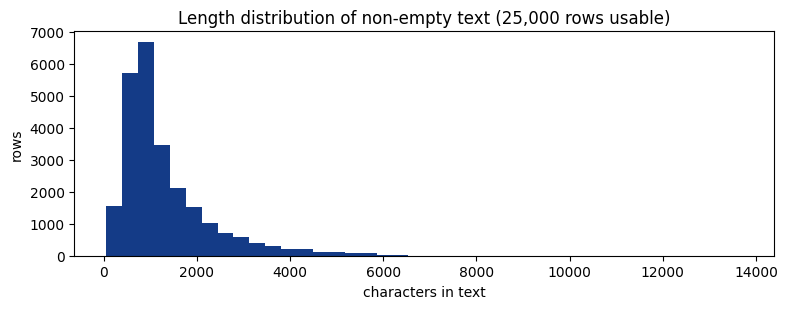


The number that matters for your dataset choice is USABLE, not the row count.


In [ ]:
# --- Part 5: the text column --------------------------------------------------
_require("part4", "Part 4 has not run. Run it first.")

import matplotlib.pyplot as plt

if TEXT_COLUMN is None:
    print("This dataset has no text column. Weeks 8 to 10 will not work on it. Say so in Part 8.")
else:
    t  = df[TEXT_COLUMN]
    ln = t.fillna("").astype(str).str.strip().str.len()
    usable = int((ln >= 20).sum())
    print(f"column                     : {TEXT_COLUMN}")
    print(f"rows total                 : {len(df):,}")
    print(f"isna()                     : {int(t.isna().sum()):,} ({t.isna().mean()*100:.1f}%)")
    print(f"blank after stripping      : {int((ln == 0).sum()):,} ({(ln==0).mean()*100:.1f}%)")
    print(f"under 20 characters        : {int((ln < 20).sum()):,} ({(ln<20).mean()*100:.1f}%)")
    print(f"USABLE for Weeks 8 to 10   : {usable:,} ({usable/len(df)*100:.1f}%)")
    print(f"\nlength of the non-empty entries:")
    print(ln[ln > 0].describe().round(1).to_string())

    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.hist(ln[ln > 0], bins=40, color="#143b87")
    ax.set_xlabel(f"characters in {TEXT_COLUMN}"); ax.set_ylabel("rows")
    ax.set_title(f"Length distribution of non-empty {TEXT_COLUMN} ({usable:,} rows usable)")
    plt.tight_layout(); plt.show()

    print("\nThe number that matters for your dataset choice is USABLE, not the row count.")
_done("part5")

---
# Parts 6 to 8: your work

Everything above was written for you. Everything below is not, and it is where all three points
live. Write inside the triple quotes.

## Part 6: Provenance

1. The **URL** of the page that describes how your data was collected.
2. A **quoted sentence** from that page about collection, **or** a plain statement that the page
   does not describe it. Both are correct. Making something up is not.
3. **One thing** the collection process systematically leaves out.

If the first page you find says nothing, follow its citation. Dataset cards usually link a paper or
a project homepage, and the real description lives there.

In [ ]:
PROVENANCE = """
Replace this text.

Quoted sentence about collection (or: this page does not describe collection): 'Reviews are labeled only when strongly positive (score ≥ 7/10) or strongly negative (score ≤ 4/10)'
One thing this process systematically excludes: Mid Value Ratings (5/6)
"""

## Part 7: Quality audit

Six rows. Each one carries **either** a number from your own profile **or** a plain statement that
the profile cannot check this dimension and what evidence outside the file would.


"The data looks fine" is not an audit row.

In [ ]:
AUDIT = """
Replace this text. Keep all six labels.

Completeness : 100% of the records are usable
Validity     : both columns have usable text
Consistency  : no pair constrains another
Timeliness   : The dataset doesn't indicate a timeline and it isn't needed to answer the question
Uniqueness   : The documentation does not name an identifier column, 0.38% of the file has duplicate values
Accuracy     : The dataset was scrubbed from IMDB

"""

## Part 8: Two questions, and a verdict

Two candidate analysis questions for **this** dataset. Say which one it can answer and which it
cannot, and name the column. Give the number of
rows where every column that question needs is usable **at the same time**: that, not the row
count, is your real sample size.

Then the verdict: is this dataset fit to carry to December, and what are its two biggest risks?

In [ ]:
QUESTIONS = """
Replace this text.

Question A: What phrases/words are tied more strongly to negative/positive opinions?
Question B: Which movie genre produces the most extreme reviews?
The one this dataset can answer, and why:
The one it cannot:
Rows usable for every column the answerable question needs, at once: 100%
"""

VERDICT = """
Yes, I believe this dataset is able to carry to December since it features a free text column and a label.
Although it only has two columns, both columns have usable text with no null values.
The dataset features only 96 duplicate values the rest of the columns are unique. The Data has a mean value of 5.0, with most of the label values equaling either 0 for negative or 1 for positive.

Is this dataset fit to carry from here to December?
Biggest risk 1: Lack of columns
Biggest risk 2: Lack of variation of labels (0/1)
"""

---
## Part 9: Self-check

Run this last. It checks that you
named a dataset, that every part ran in order in this session, that Parts 6 to 8 are filled, that
Part 6 contains a URL, and that Part 7 has all six dimension rows.

It does **not** grade your judgement.

In [ ]:
# --- Part 9: self-check -------------------------------------------------------
import re
if "part5" not in _ran:
    print("Parts 0 to 5 did not all run in this session. The report below will be incomplete.\n")
problems, notes = [], []

EXPECTED = ["part0", "todo1", "part1", "todo23", "part2", "part3", "part4", "part5"]
if _ran != EXPECTED:
    problems.append(f"parts did not run in order. expected {EXPECTED}, got {_ran}. "
                    "Runtime > Disconnect and delete runtime, then Run all.")

if "REPLACE ME" in str(DATASET_CHOICE):
    problems.append("DATASET_CHOICE still contains REPLACE ME.")

for label, text, min_words in (("PROVENANCE", PROVENANCE, 40),
                               ("AUDIT", AUDIT, 60),
                               ("QUESTIONS", QUESTIONS, 40),
                               ("VERDICT", VERDICT, 40)):
    if "Replace this text" in text:
        problems.append(f"{label} still contains the placeholder line.")
    n = len(text.split())
    if n < min_words:
        problems.append(f"{label} is {n} words; expected at least {min_words}.")

if not re.search(r"https?://\S+", PROVENANCE):
    problems.append("PROVENANCE contains no URL. Part 6 requires the page you checked.")

for dim in ("Completeness", "Validity", "Consistency", "Timeliness", "Uniqueness", "Accuracy"):
    if dim.lower() not in AUDIT.lower():
        problems.append(f"AUDIT is missing the {dim} row.")

if not re.search(r"\d", AUDIT):
    problems.append("AUDIT contains no digits. Every row needs a number from your own profile, "
                    "or an explicit statement that the profile cannot check that dimension.")
if not re.search(r"\d", QUESTIONS):
    notes.append("QUESTIONS contains no digits. Part 8 asks for the count of rows usable at once.")

print("=" * 62)
print("LAB 1 SELF-CHECK".center(62))
print("=" * 62)
print(f"dataset      : {DATASET_CHOICE.get('name')}")
print(f"documentation: {DATASET_CHOICE.get('doc_url')}")
print(f"shape        : {df.shape[0]:,} rows x {df.shape[1]} columns" if "part1" in _ran else "shape        : Part 1 never completed")
print(f"text column  : {TEXT_COLUMN}")
print(f"id column    : {ID_COLUMN if ID_COLUMN else 'none named by the documentation'}")
print(f"parts run    : {' -> '.join(_ran)}")
print("-" * 62)
if notes:
    print("WORTH A LOOK (not blocking):")
    for n_ in notes: print("  -", n_)
if problems:
    print(f"NOT READY TO SUBMIT ({len(problems)} problem(s)):")
    for p_ in problems: print("  -", p_)
    print("\nFix these, then Runtime > Run all again.")
else:
    print("ALL CHECKS PASSED")
    print("Submit: this .ipynb file AND the Colab share link.")
    print("The same link is your Project 0 'proof it loads'.")
print("=" * 62)

                       LAB 1 SELF-CHECK                       
dataset      : IMDB Movie Reviews
documentation: https://huggingface.co/datasets/stanfordnlp/imdb
shape        : 25,000 rows x 2 columns
text column  : text
id column    : none named by the documentation
parts run    : part0 -> todo1 -> part1 -> todo23 -> part2 -> part3 -> part4 -> part5
--------------------------------------------------------------
NOT READY TO SUBMIT (4 problem(s)):
  - PROVENANCE still contains the placeholder line.
  - AUDIT still contains the placeholder line.
  - QUESTIONS still contains the placeholder line.
  - PROVENANCE contains no URL. Part 6 requires the page you checked.

Fix these, then Runtime > Run all again.
